# 60 Extreme Scaling

In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import matplotlib.cm as cm
from matplotlib.colors import ListedColormap, BoundaryNorm
from collections import defaultdict

from cdrmip_extremes import (
    utils, stats, io_disk, plotting, load_raw, extremes
)
from cdrmip_extremes import (
    configs, load_pipeline, io_disk, gwl, utils,
    extremes_pipeline
)

from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
config = load_pipeline.LoadConfig(
    experiments=[
        load_pipeline.ExperimentConfig(
            experiment_id='1pctCO2-cdr', table_id='Amon', variable_id='tas',
            anomaly_reference='piControl',grid_label=None,
            overshoot=True, crossing_gwls = [1.5], gwl_match_period = (320,340),
            anomaly_time_resolution = 'native'
        ),
    ],
    realign_years_overrides={'1pctCO2': (0, 140)}
)

In [4]:
pipe = load_pipeline.LoadingPipeline(config).run()

=== Loading 1pctCO2-cdr ===
Searching for files matching: {'experiment_id': '1pctCO2-cdr', 'table_id': 'Amon', 'variable_id': 'tas', 'grid_label': None, 'member_id': None}
Loading ACCESS-ESM1-5 / r1i1p1f1
  0241-01-16 12:00:00 -> 1000-12-16 12:00:00
Loading CESM2 / r1i1p1f1
  0001-01-15 12:00:00 -> 0200-12-15 12:00:00
Loading CNRM-ESM2-1 / r1i1p1f2
  1990-01-16 12:00:00 -> 2189-12-16 12:00:00
Loading CanESM5 / r1i1p2f1
  1991-01-16 12:00:00 -> 2290-12-16 12:00:00
Loading GFDL-ESM4 / r1i1p1f1
  0141-01-16 12:00:00 -> 0340-12-16 12:00:00
Loading MIROC-ES2L / r1i1p1f2
  1989-01-16 12:00:00 -> 2490-12-16 12:00:00
Loading NorESM2-LM / r1i1p1f1
  0141-01-16 12:00:00 -> 0399-12-16 12:00:00
Loading UKESM1-0-LL / r1i1p1f2
  1990-01-16 00:00:00 -> 2639-12-16 00:00:00
Searching for ACCESS-ESM1-5 1pctCO2-cdr r1i1p1f1 parent
Loading ACCESS-ESM1-5 1pctCO2 r1i1p1f1
Concatenating 1pctCO2-cdr -> 1pctCO2 [ACCESS-ESM1-5] via realign_years=(0, 140)
Concatenating via realign_years=(0, 140) (parent relabele

In [5]:
pipe.load_gsat().compute_gsat_rolling().compute_peak_warming()

In [6]:
pipe.compute_crossing_years().compute_gwl_matching()

In [7]:
ext = extremes_pipeline.ExtremesPipeline(
    regridded_piControl=pipe.regridded_piControl,
    regridded_concat=pipe.regridded_concat,
    crossing_years=pipe.crossing_years,
    gwl_matching=pipe.gwl_matching,
    gwl_window=21
)    

In [8]:
ext.compute_extreme_months()

### Want tas data for just the extreme months

In [9]:
anom_extreme = defaultdict(lambda: defaultdict(dict))
for model, expt_dt in pipe.anomaly.items():
    for expt, member_dt in expt_dt.items():
        for member, ds in member_dt.items():
            ext_months = ext.extreme_months[model][member]
            anom_extreme[model][expt][member] = extremes.select_extreme_month(ds,ext_months)
anom_extreme = utils.defaultdict_to_dict(anom_extreme)

In [10]:
corr_maps = {'pre': {}, 'post': {}}
for model, expt_dt in anom_extreme.items():
    for expt, member_dt in expt_dt.items():
        pre_list, post_list = [], []
        for member, ds in member_dt.items():
            peak_year = pipe.peak_warming[model][expt][member]['peak_year']
            gsat_da = pipe.gsat[model][expt][member].gsat.groupby('time.year').mean(dim='time')
            end_year = int(ds.year.max())

            pre_list.append(xr.corr(ds.sel(year=slice(None, peak_year)),
                                     gsat_da.sel(year=slice(None, peak_year)), dim='year'))
            post_list.append(xr.corr(ds.sel(year=slice(peak_year, end_year)),
                                      gsat_da.sel(year=slice(peak_year, end_year)), dim='year'))

        corr_maps['pre'][model] = xr.concat(pre_list, dim='member').mean(dim='member')
        corr_maps['post'][model] = xr.concat(post_list, dim='member').mean(dim='member')

In [11]:
corr_maps = {phase: utils.add_model_reduction(d) for phase, d in corr_maps.items()}

## Perform regression of local month of maximum/mminimum temperature against GSAT

In [12]:
pre_patterns = stats.compute_pre_post_patterns(
    anom_extreme,
    pipe.gsat_rolling,
    pipe.peak_warming,
    end='peak'
)
post_patterns = stats.compute_pre_post_patterns(
    anom_extreme,
    pipe.gsat_rolling,
    pipe.peak_warming,
    start='peak'
)

In [13]:
pre_patterns = utils.reduce_models(pre_patterns)
post_patterns = utils.reduce_models(post_patterns)

# Plot regression slopes with correlation as stippling

In [14]:
def plot_regression_stat(to_plot, var, expt, period, month_type, extrema=None,
                          corr_maps=None, corr_threshold=0.9):
    fig, axes = plotting.make_geo_grid(3,3,figsize=(15,10))

    models = ['multi_model_median'] + [m for m in to_plot.keys() if m != 'multi_model_median']
    
    if var == 'slope':
        levels = np.linspace(0,2,17)
        if period == 'pre-peak':
            cmap = cm.RdBu_r
        elif period == 'post-peak':
            cmap = cm.RdBu
        else:
            cmap = cm.RdBu
    elif var == 'r2':
        levels = np.linspace(-1,1,17)
        cmap = cm.viridis
    norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)

    for model, ax in zip(models, axes.flat):
        da = to_plot[model][var].sel(extrema=extrema) if extrema is not None else to_plot[model][var]
        title = 'Multi-Model Median' if model == 'multi_model_median' else model
        im = plotting.plot_map_panel(
            ax, da,
            cmap=cmap, norm=norm,
            method='imshow', title=title,
            title_fontsize=18
        )

        if corr_maps is not None and model in corr_maps:
            corr_da = corr_maps[model]
            if extrema is not None and 'extrema' in corr_da.dims:
                corr_da = corr_da.sel(extrema=extrema)
            plotting.add_stippling(ax, corr_da.where(corr_da > corr_threshold),hatches=("/////",))

    plotting.add_colorbar(
        fig, im, rect=[0.1, -0.025, 0.8, 0.03],
        label="Local GSAT dependence (°C/°C)",
        fraction=0.02, aspect=20, orientation="horizontal",
        tick_fontsize=14, extend='both'
    )
    fig.suptitle(
        f"{expt} {period} warming month of {month_type} temperature vs GSAT regressions {var}",
        fontsize=22,
        y=1.01
    )
    fig.tight_layout()
    plt.show()
    return fig

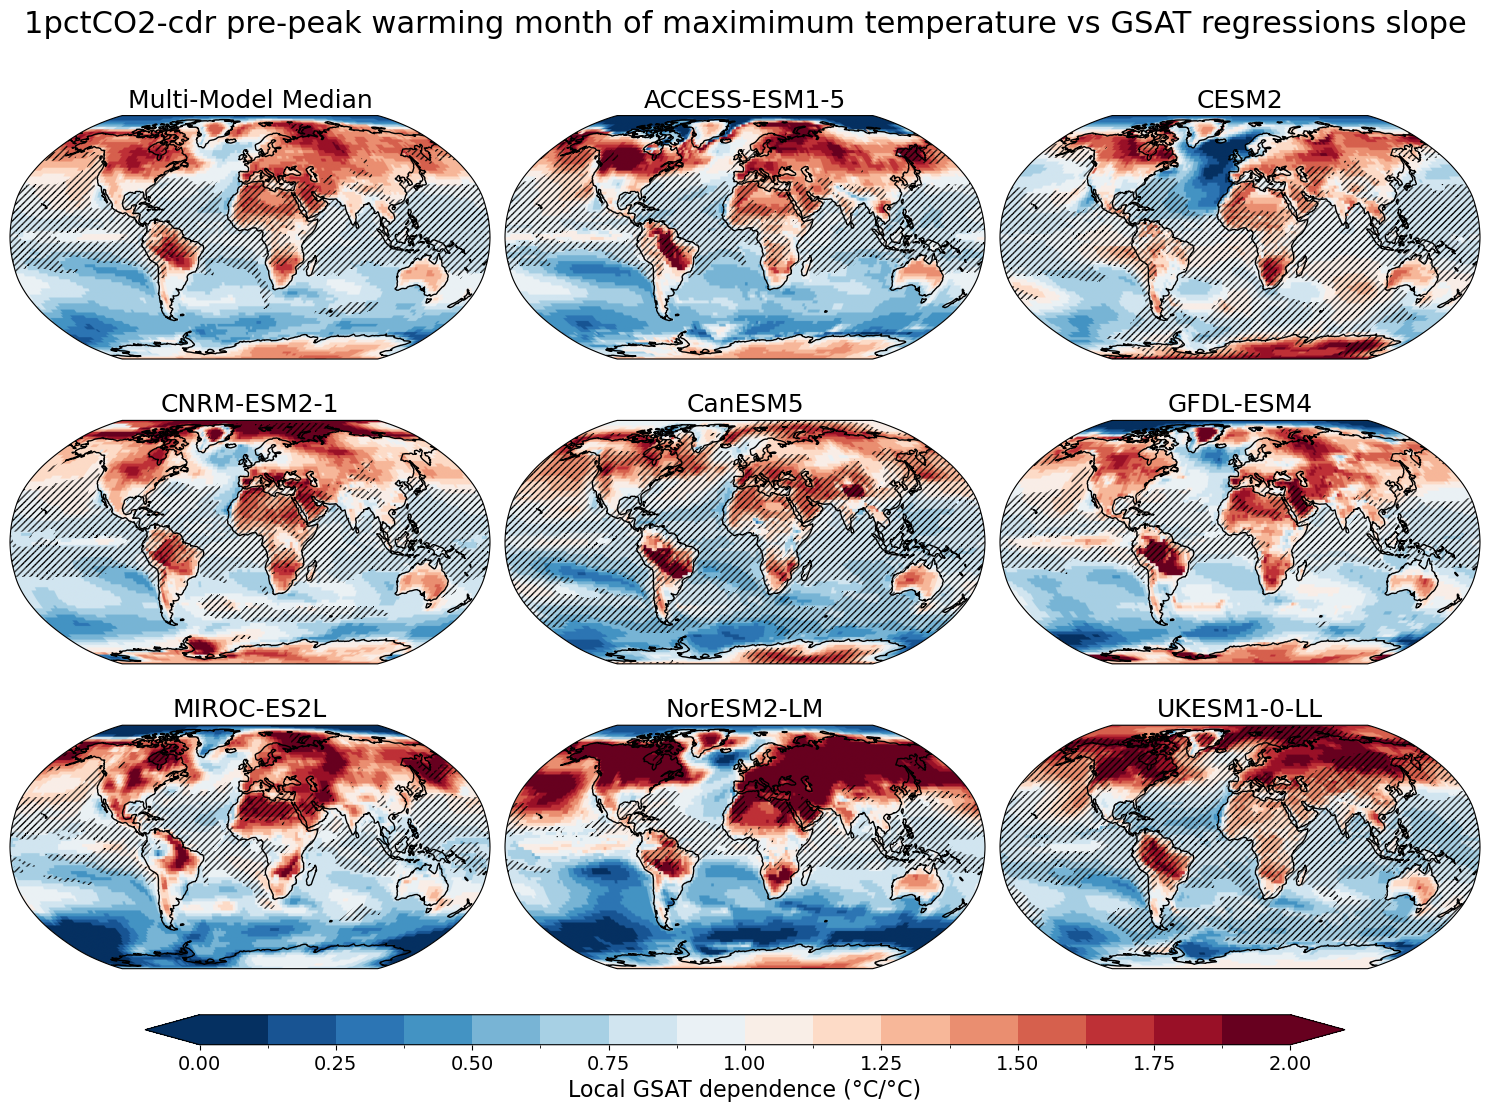

In [46]:
fig = plot_regression_stat(
    pre_patterns,
    'slope',
    '1pctCO2-cdr',
    'pre-peak',
    'maximimum',
    extrema='heat',
    corr_maps=corr_maps['pre']
)

fig.savefig(
    FIG_DIR / "supplementary" / "figure_S15.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

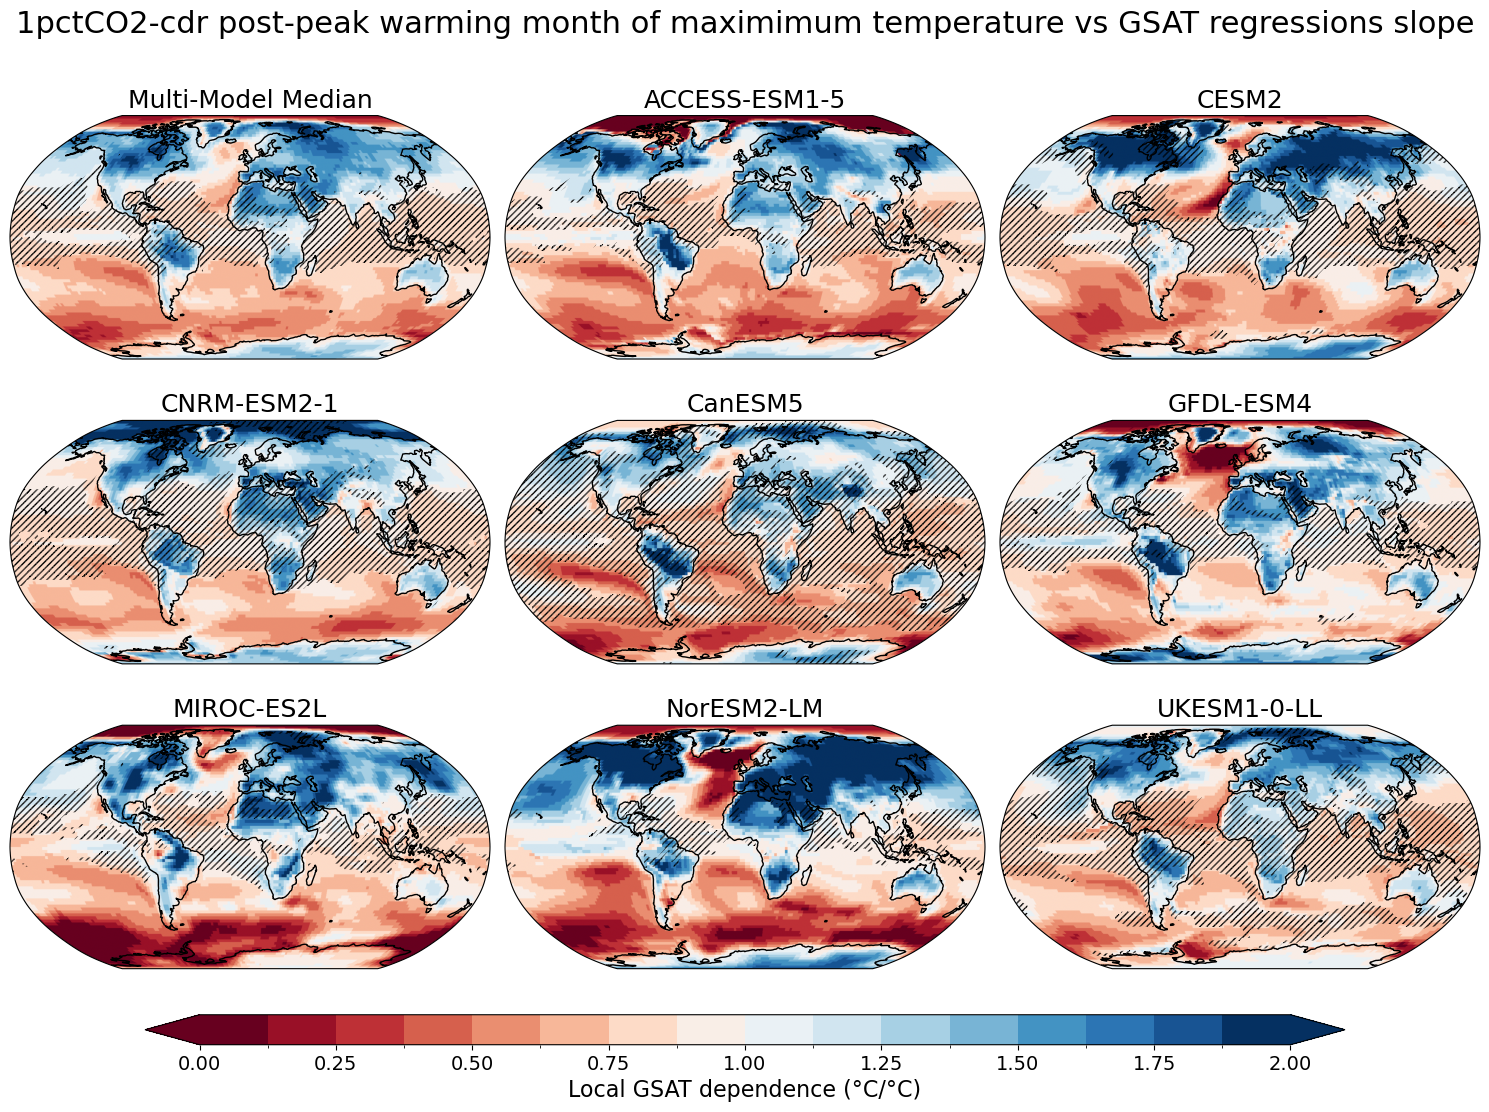

In [15]:
fig = plot_regression_stat(
    post_patterns,
    'slope',
    '1pctCO2-cdr',
    'post-peak',
    'maximimum',
    extrema='heat',
    corr_maps=corr_maps['post']
)

fig.savefig(
    FIG_DIR / "supplementary" / "figure_S16.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

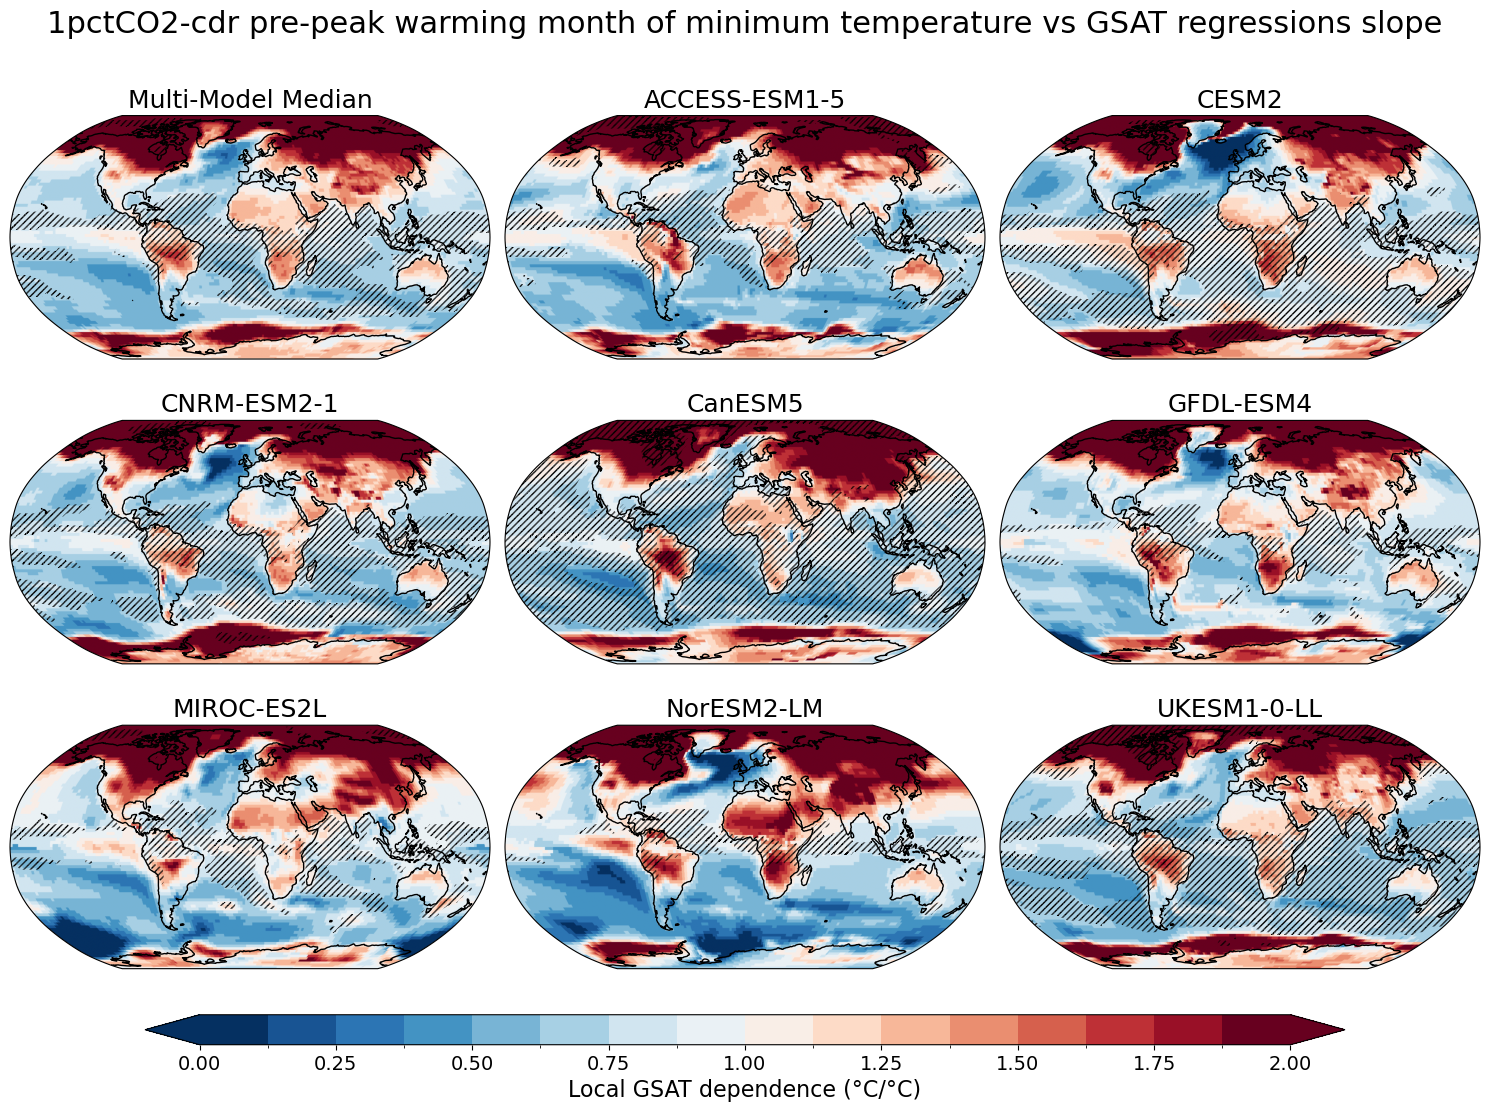

In [16]:
fig = plot_regression_stat(
    pre_patterns,
    'slope',
    '1pctCO2-cdr',
    'pre-peak',
    'minimum',
    extrema='cold',
    corr_maps=corr_maps['pre']
)

fig.savefig(
    FIG_DIR / "supplementary" / "figure_S17.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

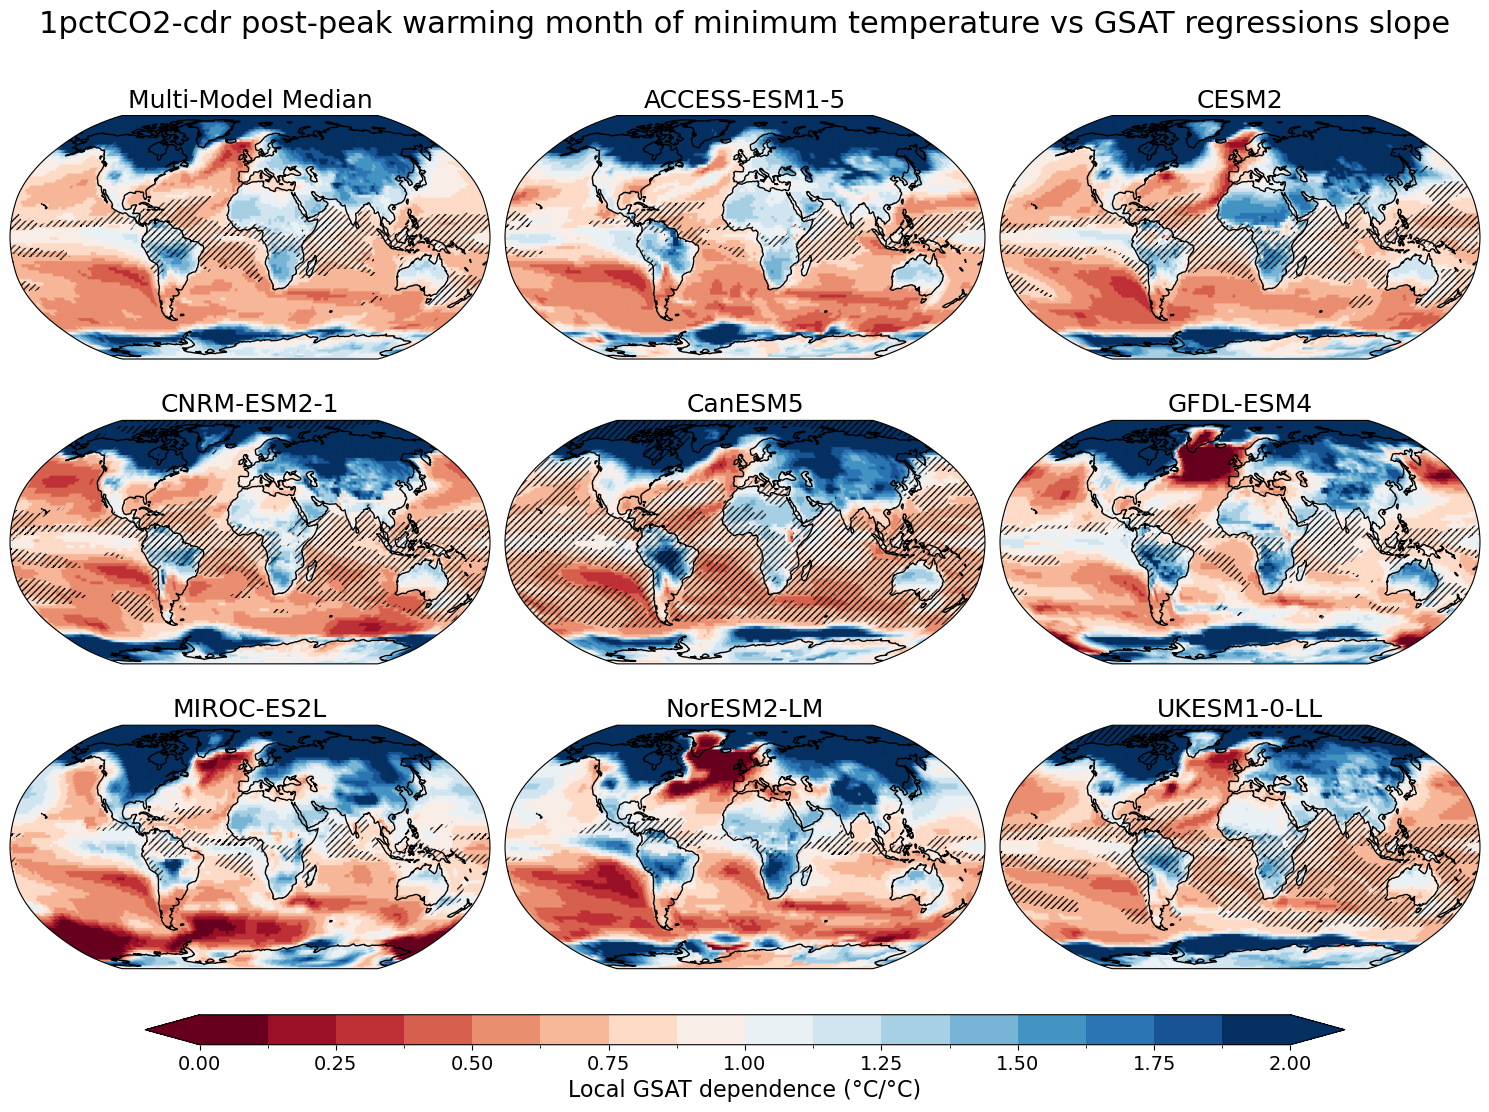

In [17]:
fig = plot_regression_stat(
    post_patterns,
    'slope',
    '1pctCO2-cdr',
    'post-peak',
    'minimum',
    extrema='cold',
    corr_maps=corr_maps['post']
)

fig.savefig(
    FIG_DIR / "supplementary" / "figure_S18.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)